# クラスごとの UMAP：k を上げると real に近づくか

- 目的：k 次までのモーメントを一致させたデータ（gram_k1〜k6）が，k を上げるほど real の分布に近づくかを可視化で確認する
- gram_k はクラスごとに，そのクラスの real のモーメントに合わせて合成されたデータなので，**クラスごとに real_c と gram_k_c を比べる**
  - real の画像を1枚ずつ編集したものではないので，サンプル単位の対応（`sample_index`）は使わない．使うのはラベルだけ
- 2通りの描き方をする
  1. **まとめて fit**（メイン）：real_c と gram_k1_c〜k6_c をまとめて1つの UMAP に fit し，同じ座標の上で k ごとに real と重ねる
     - 分布が同じなら real と混ざり，違えば離れる
  2. **real だけで fit**（比較用）：real_c に fit した reducer で gram_k_c を transform する（README の方針をクラスごとにしたもの）
     - real から外れた点も real の地図の上に押し込まれるので，離れ具合は 1 より小さく見えやすい
- `BACKEND` で GPU（cuML）/ CPU（umap-learn）を切り替える．GPU サーバー（gpu1/gpu2）では `uv sync --extra gpu` で cuML が入る

In [1]:
import glob
import os
import time

import matplotlib.pyplot as plt
import numpy as np

SERVER_DIR = os.path.expanduser("~/server/dsb_llc/input/moment_data/deletion")
TFDS_DIR = os.path.expanduser("~/tensorflow_datasets")

KS = [1, 2, 3, 4, 5, 6]
CLASS_IDS = list(range(10))
SEED = 42

cifar_classes = ["airplane", "automobile", "bird", "cat", "deer",
                 "dog", "frog", "horse", "ship", "truck"]

# k ごとの色（k が大きいほど明るい）．real は灰色
K_COLORS = {k: plt.cm.viridis(i / (len(KS) - 1)) for i, k in enumerate(KS)}
REAL_COLOR = "0.6"

# "auto": cuML（GPU）が import できればそれを使い，できなければ umap-learn（CPU）
BACKEND = "auto"
if BACKEND in ("auto", "gpu"):
    try:
        from cuml.manifold import UMAP
        BACKEND = "gpu"
    except ImportError:
        if BACKEND == "gpu":
            raise
        BACKEND = "cpu"
if BACKEND == "cpu":
    from umap import UMAP
print("backend:", BACKEND)

os.makedirs("../figures", exist_ok=True)
os.makedirs("../results", exist_ok=True)

backend: gpu


In [2]:
def load_real_cifar10():
    """real CIFAR-10 train をバイナリ版から読み込む（画素は [0, 1]，(N, 3072)，行は (32, 32, 3) を平らにしたもの）"""
    batch_dir = glob.glob(os.path.join(TFDS_DIR, "downloads", "extracted", "*", "cifar-10-batches-bin"))[0]
    rows = np.concatenate([
        np.fromfile(os.path.join(batch_dir, f"data_batch_{i}.bin"), dtype=np.uint8).reshape(-1, 3073)
        for i in range(1, 6)
    ])
    # 1行は [R 1024画素, G 1024画素, B 1024画素] なので，モーメント編集データと同じ (32, 32, 3) の並びにする
    X = rows[:, 1:].reshape(-1, 3, 32, 32).transpose(0, 2, 3, 1).reshape(len(rows), -1)
    return X.astype(np.float32) / 255.0, rows[:, 0].astype(int)


def load_moment_data(k):
    """gram_k のモーメント編集データを読み込む（(N, 3072) とラベル）"""
    path = glob.glob(os.path.join(SERVER_DIR, f"gram_k{k}", "*.npz"))[0]
    with np.load(path) as d:
        return d["pixel_values"].reshape(len(d["pixel_values"]), -1), d["original_label"].astype(int)

## データの読み込み

In [3]:
X_real, y_real = load_real_cifar10()
print("real:", X_real.shape, np.bincount(y_real))

X_moment, y_moment = {}, {}
for k in KS:
    X_moment[k], y_moment[k] = load_moment_data(k)
    print(f"k={k}:", X_moment[k].shape, np.bincount(y_moment[k]))

real: (50000, 3072) [5000 5000 5000 5000 5000 5000 5000 5000 5000 5000]


k=1: (50000, 3072) [5000 5000 5000 5000 5000 5000 5000 5000 5000 5000]


k=2: (50000, 3072) [5000 5000 5000 5000 5000 5000 5000 5000 5000 5000]


k=3: (50000, 3072) [5000 5000 5000 5000 5000 5000 5000 5000 5000 5000]


k=4: (50000, 3072) [5000 5000 5000 5000 5000 5000 5000 5000 5000 5000]


k=5: (50000, 3072) [5000 5000 5000 5000 5000 5000 5000 5000 5000 5000]


k=6: (50000, 3072) [5000 5000 5000 5000 5000 5000 5000 5000 5000 5000]


## サンプル画像
- クラスごとに real と k=1〜6 の画像を並べる（同じ列でも別の画像．対応はない）

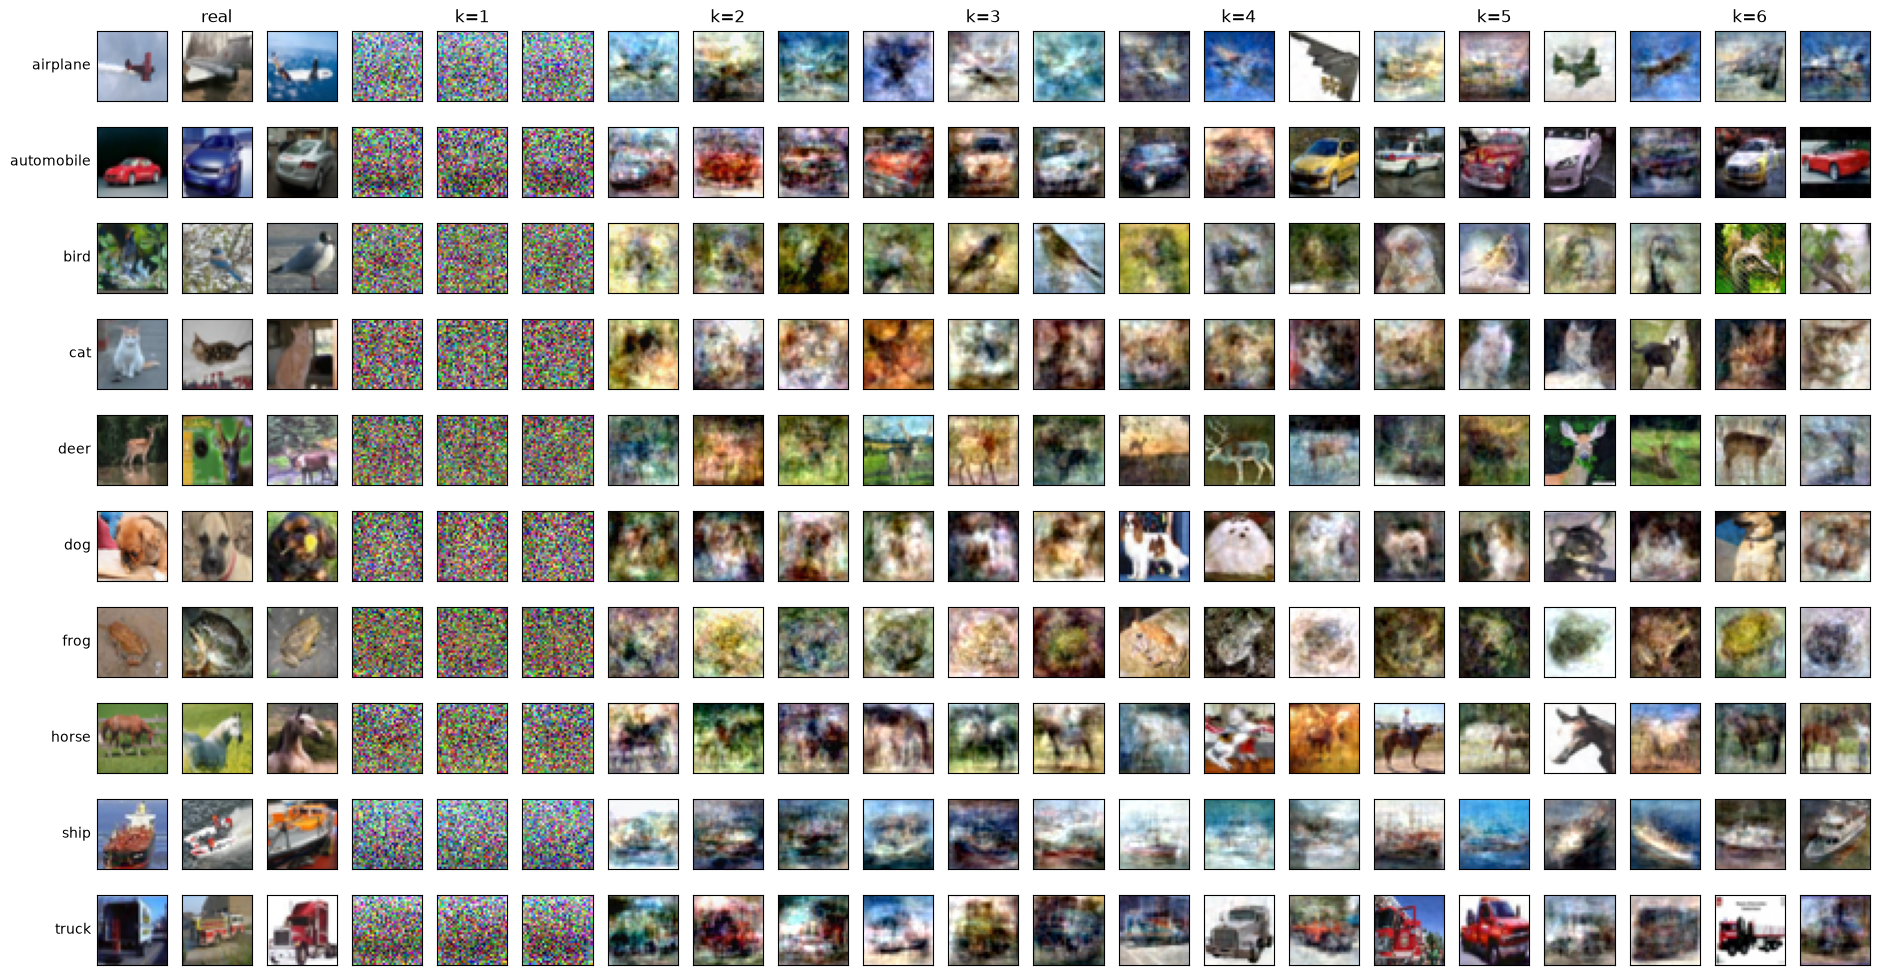

In [4]:
n_per_cell = 3  # 1条件あたりに並べる枚数
rng = np.random.default_rng(SEED)
conditions = ["real"] + KS

fig, axes = plt.subplots(len(CLASS_IDS), len(conditions) * n_per_cell,
                         figsize=(0.9 * len(conditions) * n_per_cell, 1.0 * len(CLASS_IDS)))
for r, c in enumerate(CLASS_IDS):
    for j, cond in enumerate(conditions):
        X, y = (X_real, y_real) if cond == "real" else (X_moment[cond], y_moment[cond])
        picks = rng.choice(np.flatnonzero(y == c), size=n_per_cell, replace=False)
        for i, p in enumerate(picks):
            ax = axes[r, j * n_per_cell + i]
            ax.imshow(np.clip(X[p].reshape(32, 32, 3), 0, 1))
            ax.set_xticks([])
            ax.set_yticks([])
            if r == 0 and i == 1:
                ax.set_title(cond if cond == "real" else f"k={cond}")
    axes[r, 0].set_ylabel(cifar_classes[c], rotation=0, ha="right", va="center")
plt.tight_layout()
plt.savefig("../figures/samples_per_class.png", dpi=120)

## 1. まとめて fit（メイン）
- クラスごとに real_c（5,000件）と gram_k1_c〜k6_c（各5,000件）の計35,000件を1つの UMAP に fit する
- 各パネルは同じ座標で，灰色が real，色付きがその k

In [5]:
Z_joint = {}  # Z_joint[c] = {"real": (5000, 2), 1: (5000, 2), ...}
for c in CLASS_IDS:
    groups = {"real": X_real[y_real == c]}
    groups.update({k: X_moment[k][y_moment[k] == c] for k in KS})
    X = np.concatenate(list(groups.values()))

    t0 = time.time()
    Z = np.asarray(UMAP(n_components=2, random_state=SEED).fit_transform(X))
    print(f"{cifar_classes[c]}: {X.shape}, {time.time() - t0:.1f}s")

    Z_joint[c], start = {}, 0
    for key, Xg in groups.items():
        Z_joint[c][key] = Z[start:start + len(Xg)]
        start += len(Xg)

np.savez(f"../results/umap_per_class_joint_{BACKEND}.npz",
         **{f"c{c}_{key}": z for c in CLASS_IDS for key, z in Z_joint[c].items()})

airplane: (35000, 3072), 4.9s


automobile: (35000, 3072), 4.2s


bird: (35000, 3072), 4.2s


cat: (35000, 3072), 3.8s


deer: (35000, 3072), 4.1s


dog: (35000, 3072), 4.0s


frog: (35000, 3072), 4.2s


horse: (35000, 3072), 3.1s


ship: (35000, 3072), 4.0s


truck: (35000, 3072), 4.4s


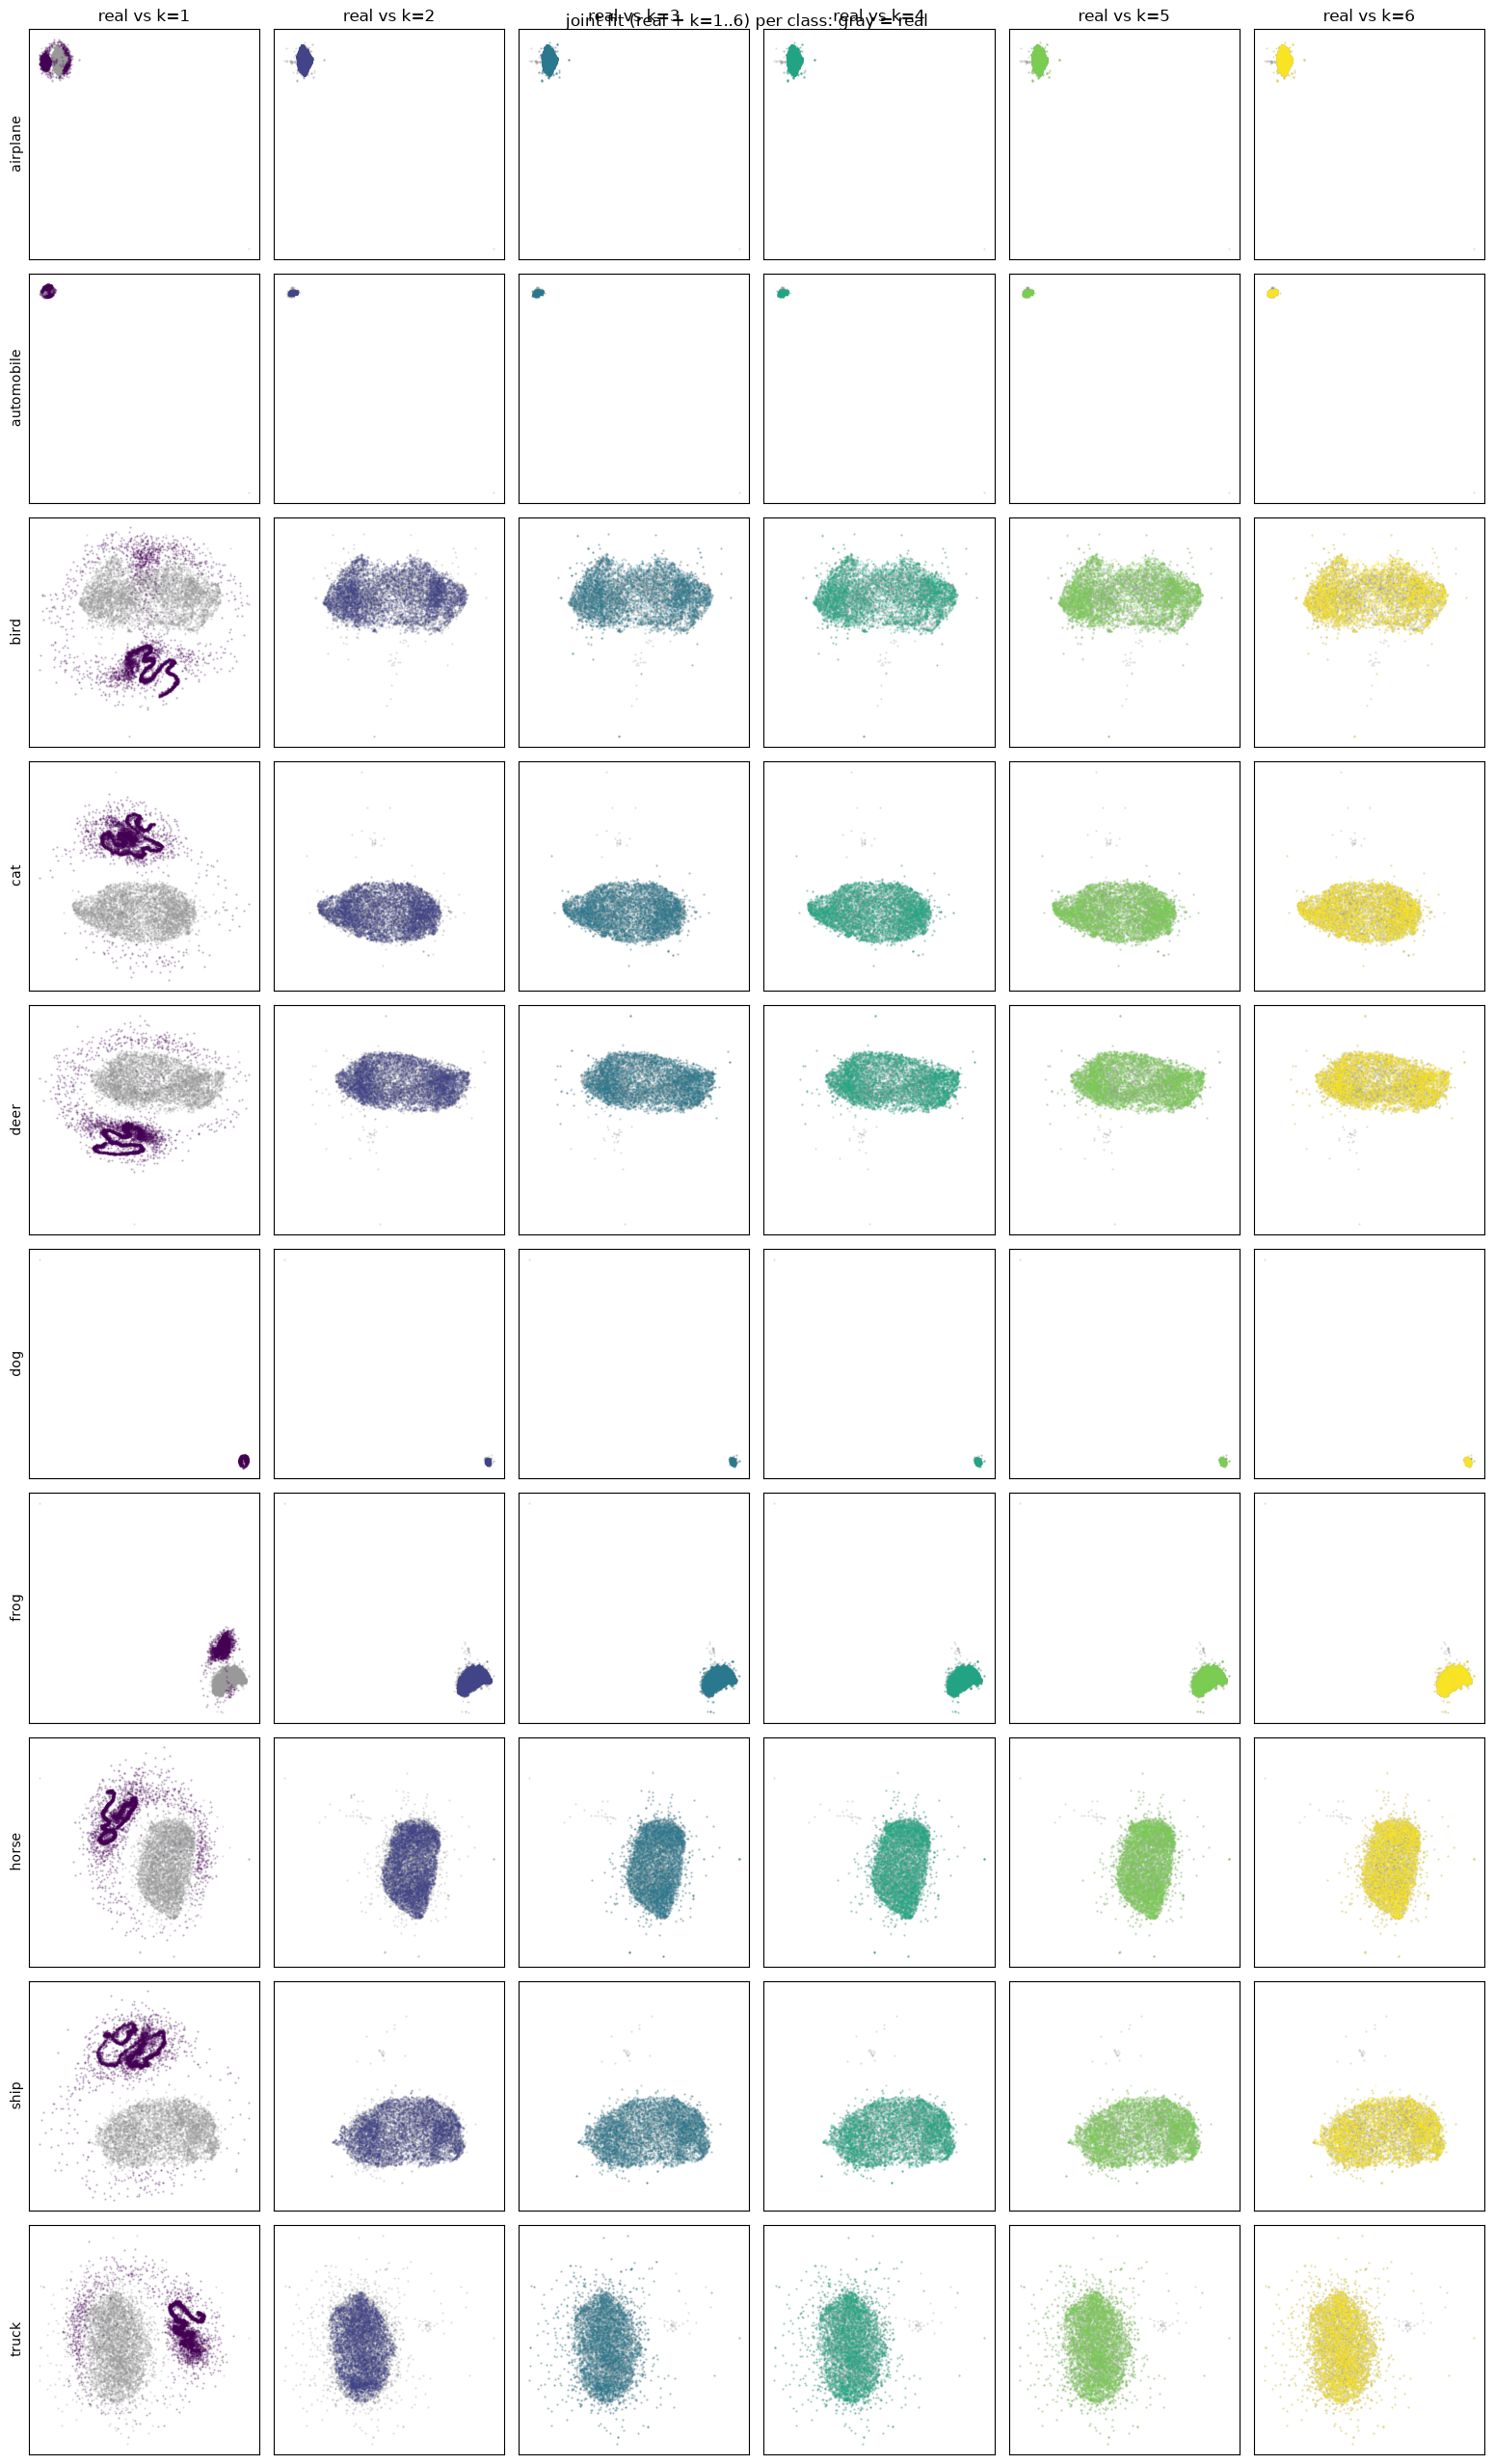

In [6]:
def plot_per_class(Z_dict, title, path):
    """行 = クラス，列 = k．各パネルに real（灰）と gram_k（色）を重ねる．同じ行は同じ座標範囲"""
    fig, axes = plt.subplots(len(CLASS_IDS), len(KS), figsize=(2.6 * len(KS), 2.6 * len(CLASS_IDS)))
    for r, c in enumerate(CLASS_IDS):
        Z_all = np.concatenate(list(Z_dict[c].values()))
        lo, hi = Z_all.min(axis=0), Z_all.max(axis=0)
        pad = 0.05 * (hi - lo)
        for j, k in enumerate(KS):
            ax = axes[r, j]
            ax.scatter(*Z_dict[c]["real"].T, s=0.3, alpha=0.3, color=REAL_COLOR, rasterized=True)
            ax.scatter(*Z_dict[c][k].T, s=0.3, alpha=0.3, color=K_COLORS[k], rasterized=True)
            ax.set_xlim(lo[0] - pad[0], hi[0] + pad[0])
            ax.set_ylim(lo[1] - pad[1], hi[1] + pad[1])
            ax.set_xticks([])
            ax.set_yticks([])
            if r == 0:
                ax.set_title(f"real vs k={k}")
        axes[r, 0].set_ylabel(cifar_classes[c])
    fig.suptitle(title)
    plt.tight_layout()
    plt.savefig(path, dpi=120)


plot_per_class(Z_joint, "joint fit (real + k=1..6) per class: gray = real",
               f"../figures/umap_per_class_joint_{BACKEND}.png")

## 2. real だけで fit（比較用）
- クラスごとに real_c だけで UMAP を fit し，その reducer で gram_k1_c〜k6_c を transform する

airplane: 0.9s


automobile: 0.9s


bird: 0.8s


cat: 0.8s


deer: 0.9s


dog: 0.9s


frog: 0.9s


horse: 0.8s


ship: 0.8s


truck: 1.0s


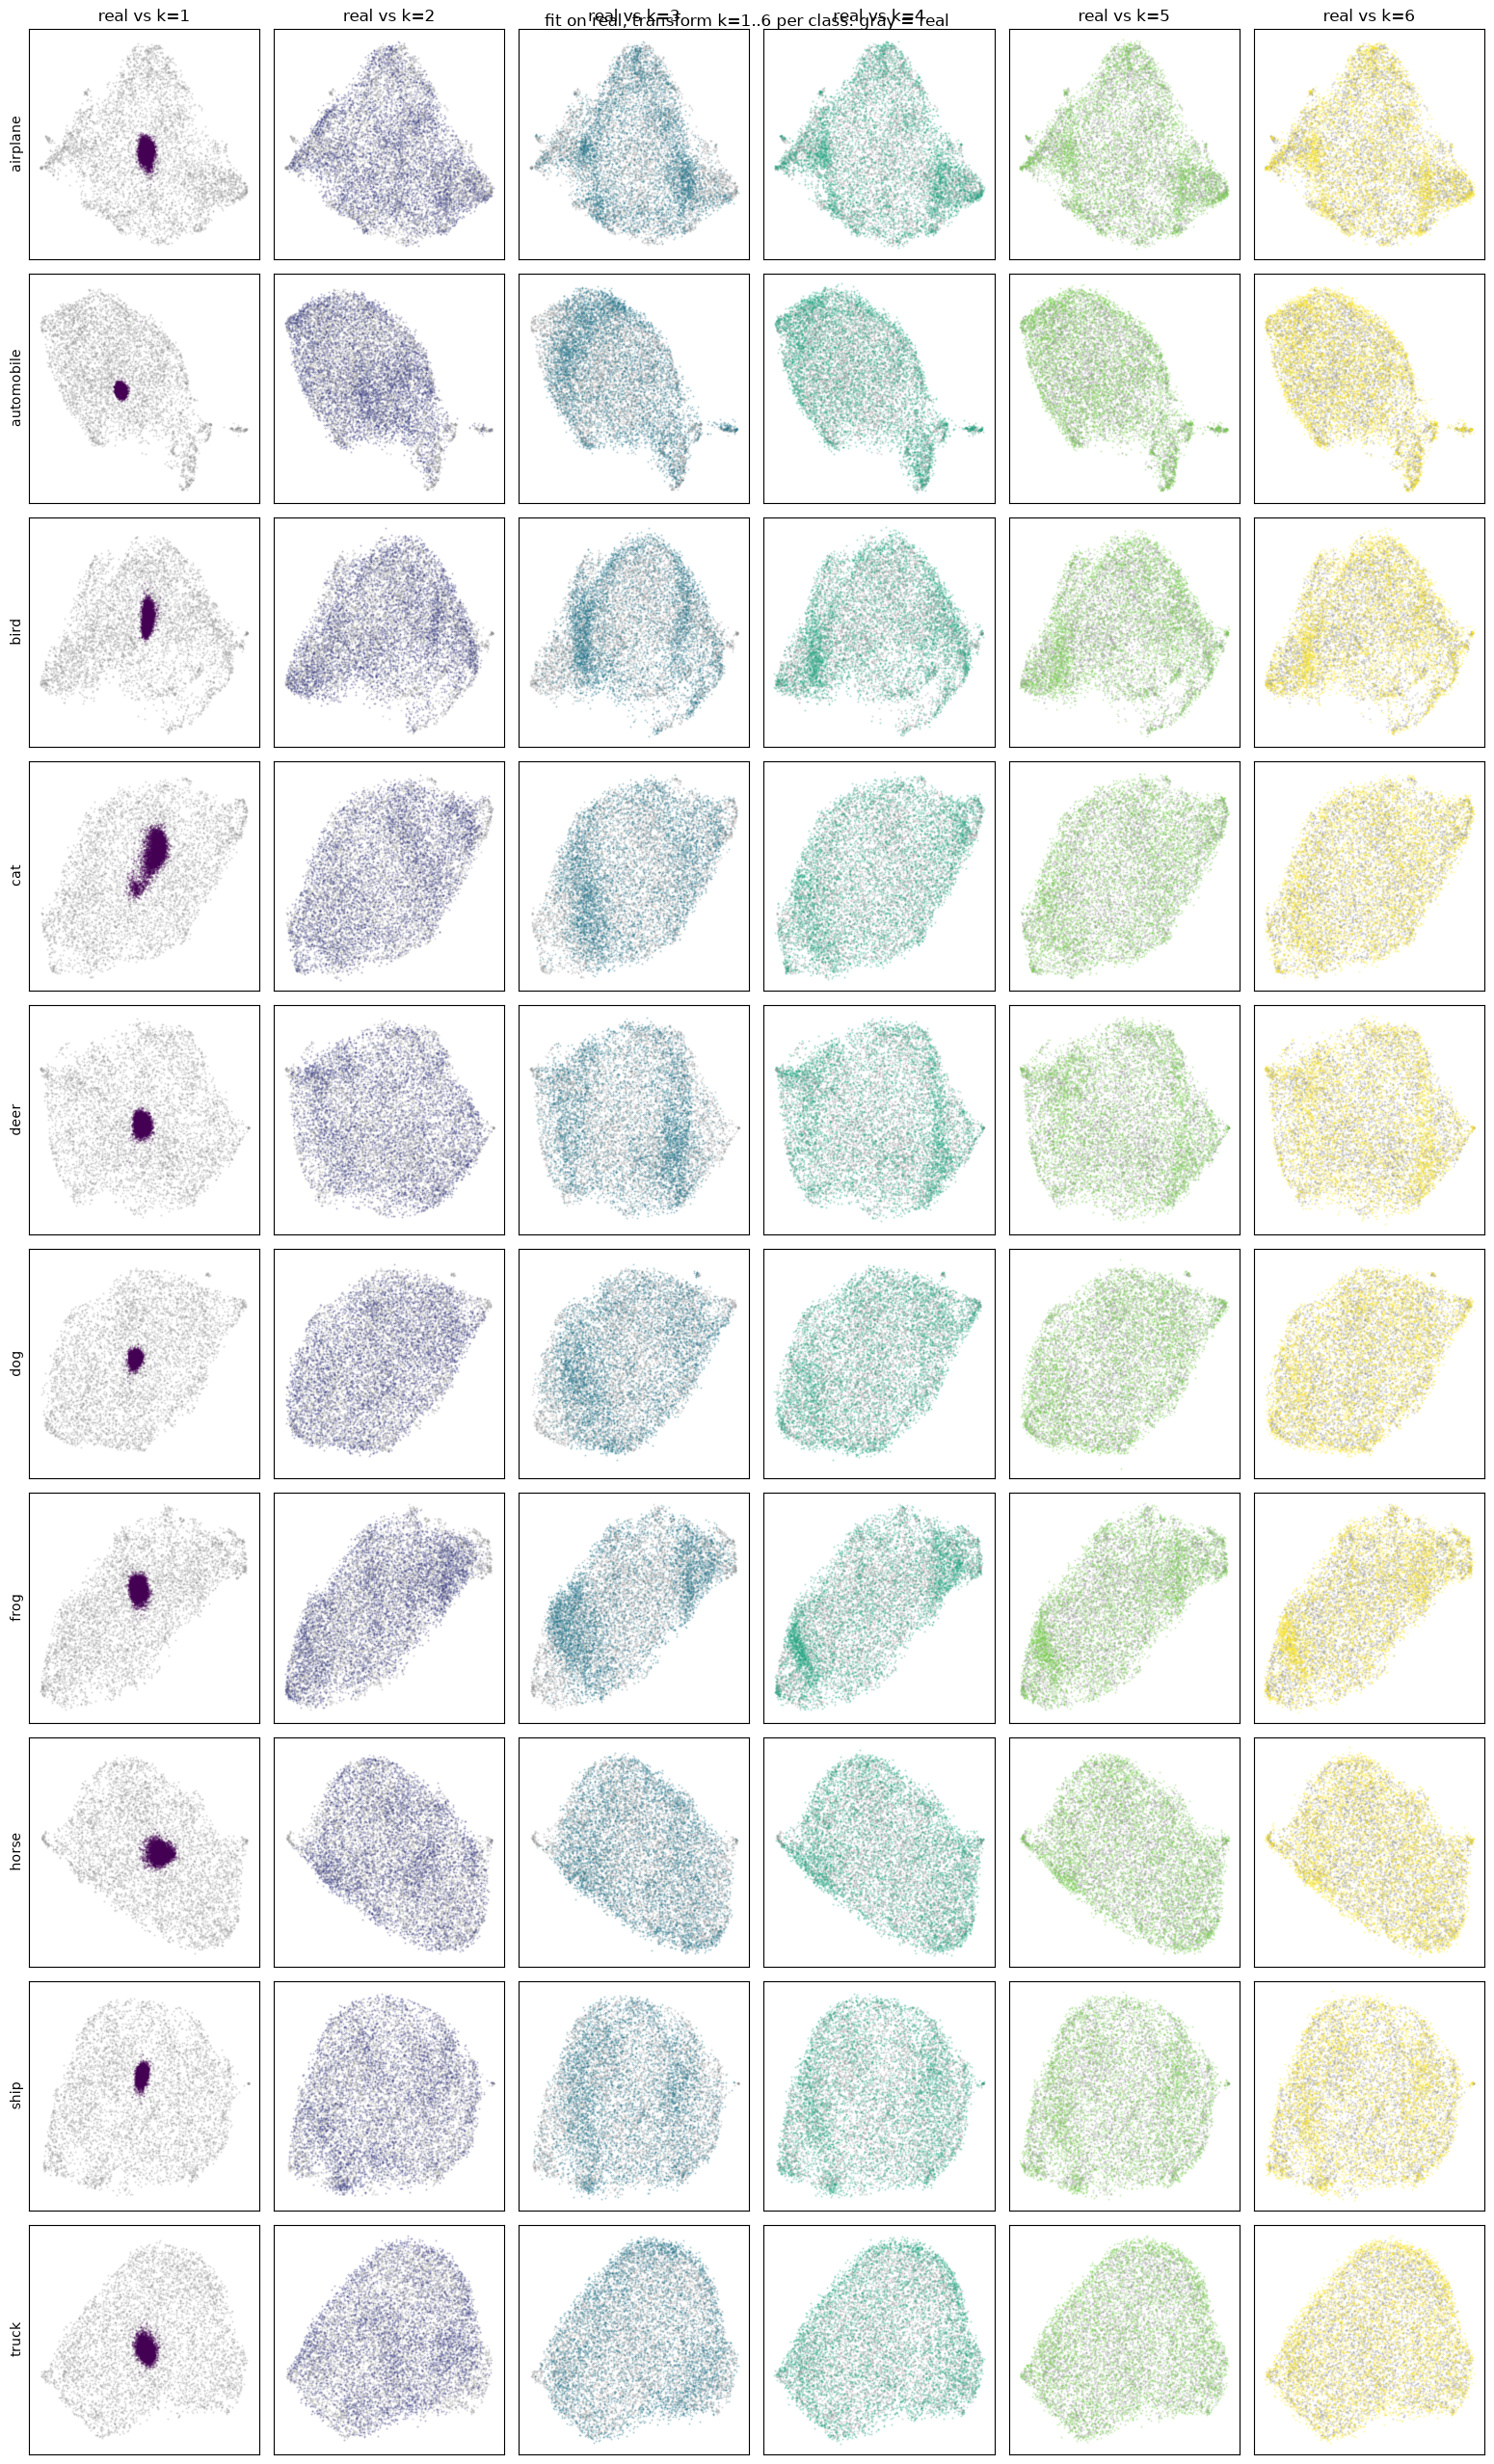

In [7]:
Z_realfit = {}
for c in CLASS_IDS:
    t0 = time.time()
    reducer = UMAP(n_components=2, random_state=SEED)
    Z_realfit[c] = {"real": np.asarray(reducer.fit_transform(X_real[y_real == c]))}
    for k in KS:
        Z_realfit[c][k] = np.asarray(reducer.transform(X_moment[k][y_moment[k] == c]))
    print(f"{cifar_classes[c]}: {time.time() - t0:.1f}s")

np.savez(f"../results/umap_per_class_realfit_{BACKEND}.npz",
         **{f"c{c}_{key}": z for c in CLASS_IDS for key, z in Z_realfit[c].items()})

plot_per_class(Z_realfit, "fit on real, transform k=1..6 per class: gray = real",
               f"../figures/umap_per_class_realfit_{BACKEND}.png")